<a href="https://colab.research.google.com/github/mehnazpa/AIML_Lab/blob/main/Regression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
from sklearn.linear_model import LinearRegression

# Input data (X)
X = np.array([[1], [2], [3], [4], [5]])

# Output data (y)
y = np.array([2, 4, 6, 8, 10])

# Create model
model = LinearRegression()

# Train model
model.fit(X, y)

# Predict
prediction = model.predict([[6]])

print("Prediction for x=6:", prediction[0])

Prediction for x=6: 12.0


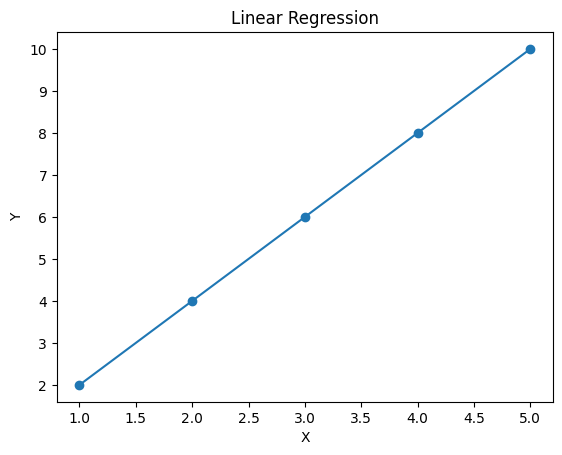

In [ ]:
import matplotlib.pyplot as plt

plt.scatter(X, y)

plt.plot(X, model.predict(X))

plt.xlabel("X")
plt.ylabel("Y")
plt.title("Linear Regression")

plt.show()

In [ ]:
import pandas as pd
from google.colab import files

uploaded = files.upload()

df = pd.read_csv("employee_pre.csv")

Saving employee_pre.csv to employee_pre.csv


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4653 entries, 0 to 4652
Data columns (total 9 columns):
 #   Column                     Non-Null Count  Dtype 
---  ------                     --------------  ----- 
 0   Education                  4653 non-null   object
 1   JoiningYear                4653 non-null   int64 
 2   City                       4653 non-null   object
 3   PaymentTier                4653 non-null   int64 
 4   Age                        4653 non-null   int64 
 5   Gender                     4653 non-null   object
 6   EverBenched                4653 non-null   object
 7   ExperienceInCurrentDomain  4653 non-null   int64 
 8   LeaveOrNot                 4653 non-null   int64 
dtypes: int64(5), object(4)
memory usage: 327.3+ KB


Slope: -0.41700763380274125
Intercept: 30.604973825276822


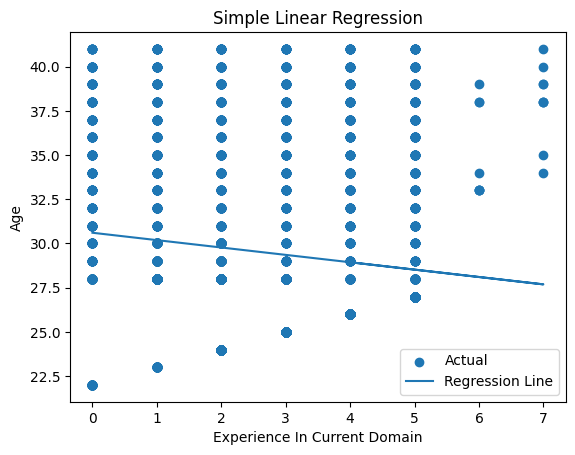

In [ ]:
# Linear regression

import pandas as pd
from sklearn.linear_model import LinearRegression
import matplotlib.pyplot as plt

X = df[["ExperienceInCurrentDomain"]]
y = df["Age"]

model = LinearRegression()
model.fit(X, y)

y_pred = model.predict(X)

print("Slope:", model.coef_[0])
print("Intercept:", model.intercept_)

plt.scatter(X, y, label="Actual")
plt.plot(X, y_pred, label="Regression Line")

plt.xlabel("Experience In Current Domain")
plt.ylabel("Age")
plt.title("Simple Linear Regression")

plt.legend()
plt.show()

In [ ]:
comparison = pd.DataFrame({
    "Actual Age": y,
    "Predicted Age": y_pred.round(2),
    "Error": (y - y_pred).round(2)
})

print(comparison.head(10))

   Actual Age  Predicted Age  Error
0          34          30.68   3.32
1          28          29.14  -1.14
2          38          29.77   8.23
3          27          28.57  -1.57
4          24          29.85  -5.85
5          22          30.65  -8.65
6          38          30.63   7.37
7          34          29.82   4.18
8          23          30.24  -7.24
9          37          29.75   7.25


R² Score: 0.009686501422758731
MSE: 22.320508928338143

First 10 Predictions:
   Actual Age  Predicted Age  Error
0          24          29.88  -5.88
1          26          28.94  -2.94
2          25          29.36  -4.36
3          28          29.75  -1.75
4          33          30.22   2.78
5          24          29.79  -5.79
6          27          28.57  -1.57
7          25          29.32  -4.32
8          28          30.29  -2.29
9          27          28.44  -1.44


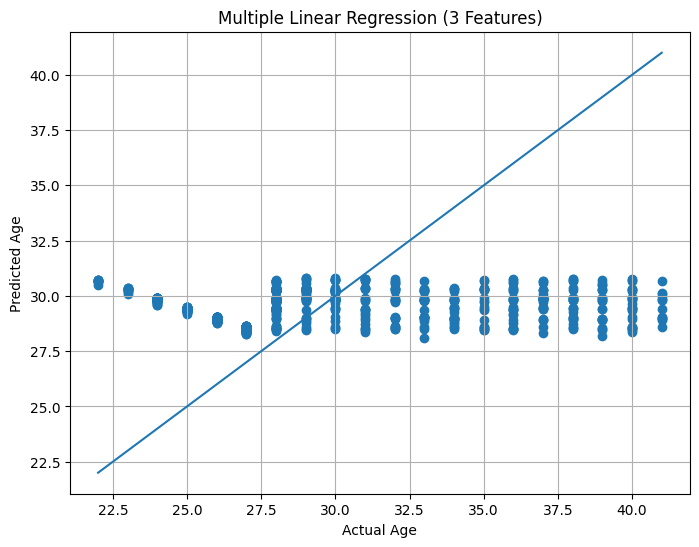

In [ ]:
# Multiple regression


import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score


# 3 Input Features
X = df[[
    "JoiningYear",
    "PaymentTier",
    "ExperienceInCurrentDomain"
]]

# Target Variable
y = df["Age"]

# Split Dataset
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

# Create and Train Model
model = LinearRegression()
model.fit(X_train, y_train)

# Predictions
y_pred = model.predict(X_test)

# Evaluation
print("R² Score:", r2_score(y_test, y_pred))
print("MSE:", mean_squared_error(y_test, y_pred))

# Comparison Table
comparison = pd.DataFrame({
    "Actual Age": y_test.values,
    "Predicted Age": y_pred.round(2),
    "Error": (y_test.values - y_pred).round(2)
})

print("\nFirst 10 Predictions:")
print(comparison.head(10))

# Graph
plt.figure(figsize=(8,6))

# Dots
plt.scatter(y_test, y_pred)

# Perfect Prediction Line (y = x)
min_val = min(y_test.min(), y_pred.min())
max_val = max(y_test.max(), y_pred.max())

plt.plot(
    [min_val, max_val],
    [min_val, max_val]
)

plt.xlabel("Actual Age")
plt.ylabel("Predicted Age")
plt.title("Multiple Linear Regression (3 Features)")

plt.grid(True)

plt.show()